# Lab 5. Transfer Learning

## Overview
Multi-class image classification (10 classes) using transfer learning.

Two approaches are implemented and compared:
1. **Feature Extraction**: freeze the base model, train only the new classification layers.
2. **Fine-Tuning**: unfreeze some top layers of the base model and continue training.

**Steps in this notebook**
0. Setup and config
1. Dataset (load, 80/20 split, inspect, load unlabeled test images)
2. Input pipeline (prefetch, augmentation, preprocessing)
3. Model (pre-trained base + new head, architecture diagram)
4. Approach 1: Feature Extraction
5. Approach 2: Fine-Tuning
6. Compare both methods (accuracy and training time) and predict on the test set
7. More models (ResNet50, DenseNet121, EfficientNetB4, ConvNeXtTiny, InceptionV3) with the same method
8. Report checklist and submission

## 0. Setup

In [1]:
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

print("TensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPUs: []


In [2]:
PARENT_DIR = "F:/SwinburneCourse/COS30082 - Applied ML/COS30082/Lab/05/Animals and Plants Dataset"          
DATA_DIR   = os.path.join(PARENT_DIR, "train")
TEST_DIR   = os.path.join(PARENT_DIR, "test")          # pictures only, no labels
SAMPLE_SUBMISSION = "F:/SwinburneCourse/COS30082 - Applied ML/COS30082/Lab/05/Animals and Plants Dataset/sample_submission.csv"   
LABEL_MAP = {'Amphibia': 1, 'Animalia': 2, 'Arachnida': 3, 'Aves': 4, 'Fungi': 5, 
             'Insecta': 6, 'Mammalia': 7, 'Mollusca': 8, 'Plantae': 9, 'Reptilia': 10}     
IMG_SIZE   = (224, 224)   # all models use the same size
BATCH_SIZE = 32
VAL_SPLIT  = 0.2        # 80/20 split
SEED       = 42
NUM_CLASSES = 10

FE_EPOCHS  = 10         # feature extraction epochs
FT_EPOCHS  = 10         # extra epochs for fine-tuning
BASE_LR    = 1e-4
UNFREEZE_FRACTION = 0.35  # top 35% of the base layers are unfrozen in fine-tuning (same for every model)

tf.keras.utils.set_random_seed(SEED)

## 1. Dataset

In [3]:
assert os.path.isdir(DATA_DIR), f"Folder not found: {DATA_DIR}"

train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=VAL_SPLIT,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
)
val_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=VAL_SPLIT,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

class_names = train_ds.class_names
print("Classes:", class_names)
assert len(class_names) == NUM_CLASSES, f"Expected {NUM_CLASSES} classes, found {len(class_names)}"
print("Train batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Val batches:  ", tf.data.experimental.cardinality(val_ds).numpy())

Found 5006 files belonging to 10 classes.
Using 4005 files for training.
Found 5006 files belonging to 10 classes.
Using 1001 files for validation.
Classes: ['Amphibia', 'Animalia', 'Arachnida', 'Aves', 'Fungi', 'Insecta', 'Mammalia', 'Mollusca', 'Plantae', 'Reptilia']
Train batches: 126
Val batches:   32


Show the first nine training images and labels.

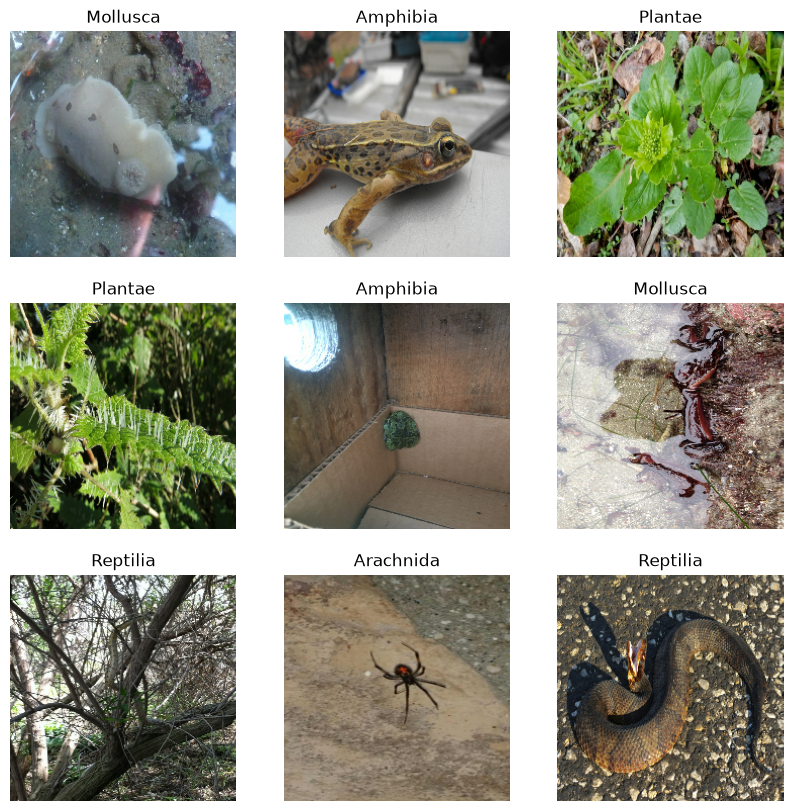

In [4]:
plt.figure(figsize=(10, 10))
for images, labels in train_ds.take(1):
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")
plt.show()

### Test set (pictures only)
The `test` folder is in the same parent folder as `train`. It has **no labels**, so it cannot give an accuracy score. It is used to check that the trained models give sensible predictions on new images.

Images are read in file order (`shuffle=False`), so each prediction matches its file name.

In [7]:
if os.path.isdir(TEST_DIR):
    test_ds = tf.keras.utils.image_dataset_from_directory(
        TEST_DIR,
        labels=None,              # no labels
        image_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        shuffle=False,
    )
    test_files = list(test_ds.file_paths)
    print("Test images:", len(test_files))
else:
    test_ds, test_files = None, []
    print("TEST_DIR not found, test set skipped:", TEST_DIR)

Found 997 files.
Test images: 997


## 2. Input pipeline

### Prefetch (avoid I/O blocking)

In [8]:
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds   = val_ds.prefetch(buffer_size=AUTOTUNE)
if test_ds is not None:
    test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

### Data augmentation
Random transformations on training images reduce overfitting. These layers are active only during training.

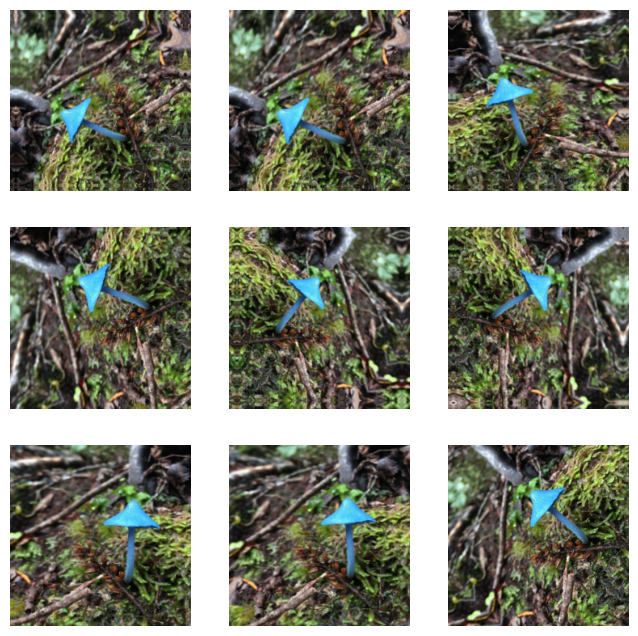

In [9]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.2),
    tf.keras.layers.RandomZoom(0.1),
], name="data_augmentation")

for images, _ in train_ds.take(1):
    plt.figure(figsize=(8, 8))
    first_image = images[0]
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        aug = data_augmentation(tf.expand_dims(first_image, 0))
        plt.imshow(aug[0].numpy().astype("uint8"))
        plt.axis("off")
    plt.show()

## 3. Model
**Pre-trained model used: MobileNetV2** (trained on ImageNet, 1.4M images, 1000 classes).

You can swap it for another network (for example `ResNet50` or `EfficientNetB4`). If you do, use the matching `preprocess_input` from the same module.

Architecture:
`Input -> Augmentation -> preprocess_input -> MobileNetV2 (no top) -> GlobalAveragePooling2D -> Dropout -> Dense(10)`

In [10]:
IMG_SHAPE = IMG_SIZE + (3,)

base_model = tf.keras.applications.MobileNetV2(
    input_shape=IMG_SHAPE,
    include_top=False,
    weights="imagenet",
)
preprocess_input = tf.keras.applications.mobilenet_v2.preprocess_input  # scales pixels to [-1, 1]

# Check what the base model outputs for one batch
image_batch, label_batch = next(iter(train_ds))
print("Base model output:", base_model(image_batch).shape)  # (batch, 7, 7, 1280) for 224x224

Base model output: (32, 7, 7, 1280)


### Build the full model

In [11]:
inputs = tf.keras.Input(shape=IMG_SHAPE)
x = data_augmentation(inputs)
x = preprocess_input(x)
x = base_model(x, training=False)          # keep BatchNorm in inference mode
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.2)(x)
outputs = tf.keras.layers.Dense(NUM_CLASSES)(x)   # logits, no activation
model = tf.keras.Model(inputs, outputs, name="transfer_model")

model.summary()

Model: "transfer_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 2,236,682 (8.53 MB)

 Non-trainable params: 34,112 (133.25 KB)

### Architecture diagram (use this image in the report)

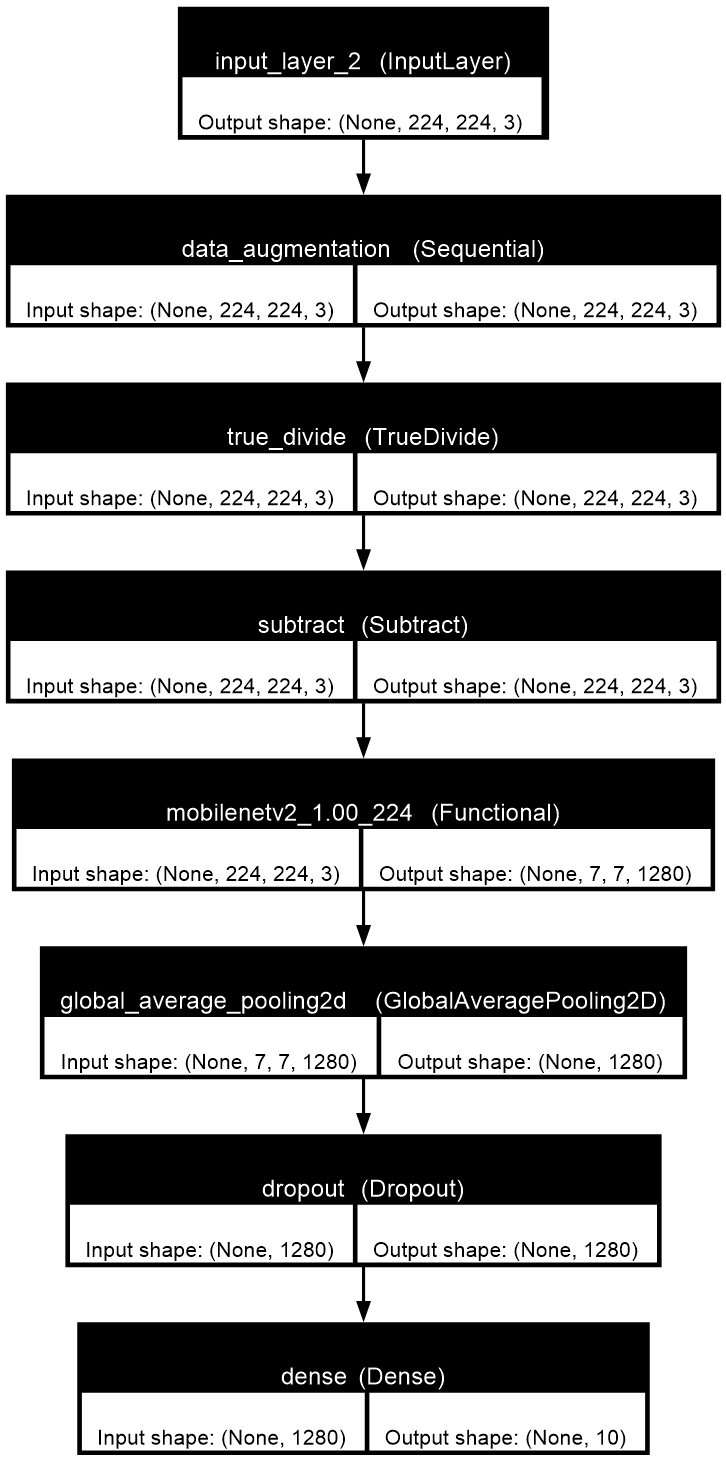

In [12]:
import pydot
import graphviz

try:
    from IPython.display import Image, display
    tf.keras.utils.plot_model(model, to_file="model_architecture.png",
                              show_shapes=True, show_layer_names=True, dpi=110)
    display(Image("model_architecture.png"))
except Exception as e:
    print("plot_model needs pydot and graphviz. Error:", e)
    print("Fix: pip install pydot  (and install graphviz), or draw the diagram by hand from model.summary().")

### Helpers
Functions to plot learning curves and read results.

In [13]:
def plot_curves(acc, val_acc, loss, val_loss, title, split_at=None):
    plt.figure(figsize=(9, 8))
    plt.subplot(2, 1, 1)
    plt.plot(acc, label="Training Accuracy")
    plt.plot(val_acc, label="Validation Accuracy")
    if split_at is not None:
        plt.axvline(split_at - 1, color="gray", linestyle="--", label="Start Fine-Tuning")
    plt.ylabel("Accuracy"); plt.legend(loc="lower right"); plt.title(title + " - Accuracy")

    plt.subplot(2, 1, 2)
    plt.plot(loss, label="Training Loss")
    plt.plot(val_loss, label="Validation Loss")
    if split_at is not None:
        plt.axvline(split_at - 1, color="gray", linestyle="--", label="Start Fine-Tuning")
    plt.ylabel("Loss"); plt.xlabel("epoch"); plt.legend(loc="upper right"); plt.title(title + " - Loss")
    plt.tight_layout(); plt.show()

def count_params(m):
    trainable = int(sum(np.prod(v.shape) for v in m.trainable_variables))
    total = int(m.count_params())
    return trainable, total

results = {}   # filled in the next sections

test_preds = {}   # model name -> predicted class index for every test image

def to_label(idx):
    # Label number written to the submission file
    cname = class_names[idx]
    if LABEL_MAP is not None:
        return int(LABEL_MAP[cname])
    return int(cname) if cname.isdigit() else int(idx)

def predict_test(m, name):
    # Predict a class for every test image. No labels, so no accuracy.
    logits = m.predict(test_ds, verbose=0)
    probs = tf.nn.softmax(logits, axis=1).numpy()
    idx = probs.argmax(axis=1)
    df = pd.DataFrame({
        "filename": [os.path.basename(p) for p in test_files],
        "class_index": idx,
        "predicted_class": [class_names[i] for i in idx],
        "confidence": probs.max(axis=1).round(4),
    })
    df.to_csv(f"test_predictions_{name}.csv", index=False)

    # Submission file in the sample format: Image_ID, Label
    sub = pd.DataFrame({
        "Image_ID": [os.path.splitext(os.path.basename(p))[0] for p in test_files],
        "Label": [to_label(i) for i in idx],
    })
    if SAMPLE_SUBMISSION and os.path.exists(SAMPLE_SUBMISSION):
        sample = pd.read_csv(SAMPLE_SUBMISSION)
        diff = set(sample["Image_ID"]) ^ set(sub["Image_ID"])
        if diff:
            print(f"[{name}] WARNING: {len(diff)} Image_ID values differ from the sample file")
        sub = sample[["Image_ID"]].merge(sub, on="Image_ID", how="left")   # same order as the sample
    else:
        sub = sub.sort_values("Image_ID")
    sub["Label"] = sub["Label"].astype("Int64")
    sub.to_csv(f"submission_{name}.csv", index=False)
    return df, idx

## 4. Approach 1: Feature Extraction
Freeze the whole base model. Only the new head (`Dense` layer) is trained.

In [14]:
base_model.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=BASE_LR),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=["accuracy"],
)

fe_trainable, fe_total = count_params(model)
print(f"Trainable params: {fe_trainable:,} / {fe_total:,}")

loss0, acc0 = model.evaluate(val_ds, verbose=0)
print(f"Before training -> val loss: {loss0:.3f}, val acc: {acc0:.3f}")

Trainable params: 12,810 / 2,270,794
Before training -> val loss: 2.539, val acc: 0.160


In [15]:
t0 = time.perf_counter()
history_fe = model.fit(train_ds, epochs=FE_EPOCHS, validation_data=val_ds)
fe_time = time.perf_counter() - t0
print(f"\nFeature extraction training time: {fe_time:.1f} s")

Epoch 1/10


c:\Users\Admin\anaconda3\envs\COS30082Lab\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


126/126 ━━━━━━━━━━━━━━━━━━━━ 40s 293ms/step - accuracy: 0.1633 - loss: 2.4176 - val_accuracy: 0.3057 - val_loss: 2.0148
Epoch 2/10
126/126 ━━━━━━━━━━━━━━━━━━━━ 37s 293ms/step - accuracy: 0.3241 - loss: 1.9617 - val_accuracy: 0.4725 - val_loss: 1.6491
Epoch 3/10
126/126 ━━━━━━━━━━━━━━━━━━━━ 38s 300ms/step - accuracy: 0.4385 - loss: 1.6654 - val_accuracy: 0.5744 - val_loss: 1.4499
Epoch 4/10
126/126 ━━━━━━━━━━━━━━━━━━━━ 34s 268ms/step - accuracy: 0.5059 - loss: 1.4884 - val_accuracy: 0.6024 - val_loss: 1.3485
Epoch 5/10
126/126 ━━━━━━━━━━━━━━━━━━━━ 31s 248ms/step - accuracy: 0.5546 - loss: 1.3645 - val_accuracy: 0.6324 - val_loss: 1.2617
Epoch 6/10
126/126 ━━━━━━━━━━━━━━━━━━━━ 32s 256ms/step - accuracy: 0.5733 - loss: 1.2995 - val_accuracy: 0.6414 - val_loss: 1.2222
Epoch 7/10
123/126 ━━━━━━━━━━━━━━━━━━━━ 0s 216ms/step - accuracy: 0.5945 - loss: 1.2407

KeyboardInterrupt: 

In [ ]:
h = history_fe.history
plot_curves(h["accuracy"], h["val_accuracy"], h["loss"], h["val_loss"], "Feature Extraction")

results["Feature Extraction"] = {
    "Val accuracy": h["val_accuracy"][-1],
    "Val loss": h["val_loss"][-1],
    "Train accuracy": h["accuracy"][-1],
    "Epochs": FE_EPOCHS,
    "Training time (s)": fe_time,
    "Trainable params": fe_trainable,
}

## 5. Approach 2: Fine-Tuning
Unfreeze the top layers of the base model and continue training the model from Section 4.
Use a **lower learning rate** (here 10x lower) so the pre-trained weights are only adjusted slightly.

In [ ]:
base_model.trainable = True
print("Layers in base model:", len(base_model.layers))

FINE_TUNE_AT = int(len(base_model.layers) * (1 - UNFREEZE_FRACTION))
print("Fine-tune from layer:", FINE_TUNE_AT)

# Freeze everything before FINE_TUNE_AT, keep the top layers trainable
for layer in base_model.layers[:FINE_TUNE_AT]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=BASE_LR / 10),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=["accuracy"],
)

ft_trainable, ft_total = count_params(model)
print(f"Trainable params: {ft_trainable:,} / {ft_total:,}")

In [ ]:
total_epochs = FE_EPOCHS + FT_EPOCHS

t0 = time.perf_counter()
history_ft = model.fit(
    train_ds,
    epochs=total_epochs,
    initial_epoch=FE_EPOCHS,      # continue from where Section 4 stopped
    validation_data=val_ds,
)
ft_time = time.perf_counter() - t0
print(f"\nFine-tuning training time (extra): {ft_time:.1f} s")

In [ ]:
hf = history_ft.history
acc      = h["accuracy"]     + hf["accuracy"]
val_acc  = h["val_accuracy"] + hf["val_accuracy"]
loss     = h["loss"]         + hf["loss"]
val_loss = h["val_loss"]     + hf["val_loss"]

plot_curves(acc, val_acc, loss, val_loss, "Feature Extraction + Fine-Tuning", split_at=FE_EPOCHS)

results["Fine-Tuning"] = {
    "Val accuracy": hf["val_accuracy"][-1],
    "Val loss": hf["val_loss"][-1],
    "Train accuracy": hf["accuracy"][-1],
    "Epochs": FT_EPOCHS,
    "Training time (s)": ft_time,
    "Trainable params": ft_trainable,
}

## 6. Comparison: Feature Extraction vs Fine-Tuning
Fine-tuning starts from the feature-extraction model, so its **total** cost is the sum of both phases.

In [ ]:
df = pd.DataFrame(results).T
df.loc["Fine-Tuning (total, FE + FT)"] = {
    "Val accuracy": results["Fine-Tuning"]["Val accuracy"],
    "Val loss": results["Fine-Tuning"]["Val loss"],
    "Train accuracy": results["Fine-Tuning"]["Train accuracy"],
    "Epochs": FE_EPOCHS + FT_EPOCHS,
    "Training time (s)": fe_time + ft_time,
    "Trainable params": ft_trainable,
}
display_df = df.copy()
display_df["Val accuracy"] = (display_df["Val accuracy"] * 100).round(2).astype(str) + " %"
display_df["Train accuracy"] = (display_df["Train accuracy"] * 100).round(2).astype(str) + " %"
display_df["Val loss"] = display_df["Val loss"].round(4)
display_df["Training time (s)"] = display_df["Training time (s)"].round(1)
display_df

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
names = ["Feature Extraction", "Fine-Tuning"]

ax[0].bar(names, [results[n]["Val accuracy"] * 100 for n in names], color=["#4C78A8", "#F58518"])
ax[0].set_ylabel("Validation accuracy (%)"); ax[0].set_title("Accuracy")
lo = min(results[n]["Val accuracy"] for n in names) * 100
ax[0].set_ylim(max(0, lo - 10), 100)

ax[1].bar(names, [results[n]["Training time (s)"] for n in names], color=["#4C78A8", "#F58518"])
ax[1].set_ylabel("Training time (s)"); ax[1].set_title("Training time")
plt.tight_layout(); plt.show()

In [ ]:
fe, ft = results["Feature Extraction"], results["Fine-Tuning"]
diff = (ft["Val accuracy"] - fe["Val accuracy"]) * 100
print(f"Feature Extraction: val acc {fe['Val accuracy']*100:.2f}%, time {fe['Training time (s)']:.1f}s, trainable params {fe['Trainable params']:,}")
print(f"Fine-Tuning:        val acc {ft['Val accuracy']*100:.2f}%, time {ft['Training time (s)']:.1f}s (extra), trainable params {ft['Trainable params']:,}")
print(f"Accuracy change from fine-tuning: {diff:+.2f} points")
print(f"Total time (FE + FT): {fe['Training time (s)'] + ft['Training time (s)']:.1f}s")

### Predict on the test set (MobileNetV2, after fine-tuning)
Saves two files: `submission_MobileNetV2.csv` (columns `Image_ID`, `Label`, same format as the sample submission) and `test_predictions_MobileNetV2.csv` (with class name and confidence). Also shows the first 12 test images.

In [ ]:
if test_ds is not None:
    test_df, test_idx = predict_test(model, "MobileNetV2")
    test_preds["MobileNetV2"] = test_idx
    print(test_df.head(10))
    print()
    print("Submission file (submission_MobileNetV2.csv):")
    print(pd.read_csv("submission_MobileNetV2.csv").head())
    print()
    print("Predicted class counts:")
    print(test_df["predicted_class"].value_counts())

    plt.figure(figsize=(12, 9))
    for batch in test_ds.take(1):
        for i in range(min(12, len(batch))):
            plt.subplot(3, 4, i + 1)
            plt.imshow(batch[i].numpy().astype("uint8"))
            plt.title(f"{test_df.predicted_class[i]} ({test_df.confidence[i]:.2f})", fontsize=9)
            plt.axis("off")
    plt.tight_layout(); plt.show()
else:
    print("No test set loaded.")

## 7. More models: the same method on 5 other networks
Same procedure for every model:
1. Frozen base + new head (`GlobalAveragePooling2D -> Dropout -> Dense(10)`) -> **feature extraction** for `FE_EPOCHS`
2. Unfreeze the top `UNFREEZE_FRACTION` of the base layers, learning rate 10x lower -> **fine-tuning** for `FT_EPOCHS` more

| Model | Source | Preprocessing |
|---|---|---|
| ResNet50 | `keras.applications` | `resnet50.preprocess_input` |
| DenseNet121 | `keras.applications` | `densenet.preprocess_input` |
| EfficientNetB4 | `keras.applications` | built into the network (0-255 input) |
| ConvNeXtTiny | `keras.applications` | built into the network (0-255 input) |
| InceptionV3 | `keras.applications` | `inception_v3.preprocess_input` |

MobileNetV2 results come from Sections 4-6, so it is not trained again.

**Notes**
- All models use the same image size (224x224) and the same split, so the comparison is fair.
- This section takes a long time. Lower `FE_EPOCHS` / `FT_EPOCHS` in the config or edit `MODELS_TO_RUN` to test quickly.
- Fine-tuning unfreezes the top 35% of `base.layers`. Layer counts differ (ResNet50 175, DenseNet121 427), so the share of trainable *parameters* differs between models. The table reports `Trainable FT (M)` so you can mention this in the report.

### Model registry and shared builder

In [ ]:
def identity(x):
    return x   # these networks already rescale 0-255 inputs inside the model

def get_resnet50():
    base = tf.keras.applications.ResNet50(input_shape=IMG_SHAPE, include_top=False, weights="imagenet")
    return base, tf.keras.applications.resnet50.preprocess_input

def get_densenet121():
    base = tf.keras.applications.DenseNet121(input_shape=IMG_SHAPE, include_top=False, weights="imagenet")
    return base, tf.keras.applications.densenet.preprocess_input

def get_efficientnetb4():
    base = tf.keras.applications.EfficientNetB4(input_shape=IMG_SHAPE, include_top=False, weights="imagenet")
    return base, identity

def get_convnext_tiny():
    base = tf.keras.applications.ConvNeXtTiny(input_shape=IMG_SHAPE, include_top=False, weights="imagenet")
    return base, identity

def get_inception_v3():
    base = tf.keras.applications.InceptionV3(input_shape=IMG_SHAPE, include_top=False, weights="imagenet")
    return base, tf.keras.applications.inception_v3.preprocess_input

MODEL_REGISTRY = {
    "ResNet50": get_resnet50,
    "DenseNet121": get_densenet121,
    "EfficientNetB4": get_efficientnetb0,
    "ConvNeXtTiny": get_convnext_tiny,
    "InceptionV3": get_inception_v3,
}

def build_model(base, preprocess, name):
    inputs = tf.keras.Input(shape=IMG_SHAPE)
    x = data_augmentation(inputs)
    x = preprocess(x)
    x = base(x, training=False)                        # keep BatchNorm in inference mode
    if len(x.shape) == 4:                              # feature map -> vector
        x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dropout(0.2)(x)
    outputs = tf.keras.layers.Dense(NUM_CLASSES)(x)    # logits
    return tf.keras.Model(inputs, outputs, name=name)

def make_result(total_params, fe_hist, ft_hist, fe_time, ft_time, fe_trainable, ft_trainable):
    return {
        "Params (M)": total_params / 1e6,
        "FE val acc": fe_hist["val_accuracy"][-1],
        "FT val acc": ft_hist["val_accuracy"][-1],
        "FE time (s)": fe_time,
        "FT time (s)": ft_time,
        "Total time (s)": fe_time + ft_time,
        "Trainable FE (M)": fe_trainable / 1e6,
        "Trainable FT (M)": ft_trainable / 1e6,
    }

def run_experiment(name, get_base):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    base, preprocess = get_base()
    m = build_model(base, preprocess, name)
    loss_fn = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)

    # ---- Phase 1: feature extraction ----
    base.trainable = False
    m.compile(optimizer=tf.keras.optimizers.Adam(BASE_LR), loss=loss_fn, metrics=["accuracy"])
    fe_trainable, total = count_params(m)
    print(f"[{name}] feature extraction | trainable {fe_trainable:,} / {total:,}")
    t0 = time.perf_counter()
    fe_hist = m.fit(train_ds, epochs=FE_EPOCHS, validation_data=val_ds, verbose=2).history
    fe_time = time.perf_counter() - t0

    # ---- Phase 2: fine-tuning ----
    base.trainable = True
    n = len(base.layers)
    cut = min(int(n * (1 - UNFREEZE_FRACTION)), n - 1)
    for layer in base.layers[:cut]:
        layer.trainable = False
    m.compile(optimizer=tf.keras.optimizers.Adam(BASE_LR / 10), loss=loss_fn, metrics=["accuracy"])
    ft_trainable, _ = count_params(m)
    print(f"[{name}] fine-tuning from layer {cut} of {n} | trainable {ft_trainable:,} / {total:,}")
    t0 = time.perf_counter()
    ft_hist = m.fit(train_ds, epochs=FE_EPOCHS + FT_EPOCHS, initial_epoch=FE_EPOCHS,
                    validation_data=val_ds, verbose=2).history
    ft_time = time.perf_counter() - t0

    if test_ds is not None:
        _, test_preds[name] = predict_test(m, name)

    result = make_result(total, fe_hist, ft_hist, fe_time, ft_time, fe_trainable, ft_trainable)
    return result, {"fe": fe_hist, "ft": ft_hist}

### Add the MobileNetV2 results from Sections 4-6

In [ ]:
all_results, all_histories = {}, {}

all_results["MobileNetV2"] = make_result(fe_total, h, hf, fe_time, ft_time, fe_trainable, ft_trainable)
all_histories["MobileNetV2"] = {"fe": h, "ft": hf}
print("MobileNetV2 added.")

### Train the other models
Results are saved to `model_comparison.csv` after each model. If the runtime stops, run this cell again. Models that are already done are skipped.

In [ ]:
MODELS_TO_RUN = ["ResNet50", "DenseNet121", "EfficientNetB4", "ConvNeXtTiny", "InceptionV3"]

for name in MODELS_TO_RUN:
    if name in all_results:
        print(f"{name}: already done, skipping")
        continue
    print("=" * 70)
    print(name)
    try:
        all_results[name], all_histories[name] = run_experiment(name, MODEL_REGISTRY[name])
        pd.DataFrame(all_results).T.to_csv("model_comparison.csv")
    except Exception as e:
        print(f"SKIPPED {name}: {type(e).__name__}: {e}")

### Validation curves for all models

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for name, hist in all_histories.items():
    ax[0].plot(hist["fe"]["val_accuracy"] + hist["ft"]["val_accuracy"], label=name)
    ax[1].plot(hist["fe"]["val_loss"] + hist["ft"]["val_loss"], label=name)
for a, t in zip(ax, ["Validation accuracy", "Validation loss"]):
    a.axvline(FE_EPOCHS - 0.5, color="gray", linestyle="--")
    a.set_title(t + " (dashed line = start of fine-tuning)")
    a.set_xlabel("epoch")
ax[0].legend(loc="lower right")
plt.tight_layout(); plt.show()

## Comparison table: all models

In [ ]:
cmp = pd.DataFrame(all_results).T
cmp["Gain"] = (cmp["FT val acc"] - cmp["FE val acc"]) * 100
cmp = cmp.sort_values("FT val acc", ascending=False)

summary_table = pd.DataFrame({
    "Params (M)": cmp["Params (M)"].round(1),
    "FE val acc (%)": (cmp["FE val acc"] * 100).round(2),
    "FT val acc (%)": (cmp["FT val acc"] * 100).round(2),
    "Gain (pts)": cmp["Gain"].round(2),
    "FE time (s)": cmp["FE time (s)"].round(1),
    "FT time (s)": cmp["FT time (s)"].round(1),
    "Total time (s)": cmp["Total time (s)"].round(1),
    "Trainable FE (M)": cmp["Trainable FE (M)"].round(2),
    "Trainable FT (M)": cmp["Trainable FT (M)"].round(2),
})
summary_table.to_csv("model_comparison_summary.csv")
summary_table

In [ ]:
names = list(cmp.index)
x = np.arange(len(names))
w = 0.38

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))

ax[0].bar(x - w / 2, cmp["FE val acc"] * 100, w, label="Feature Extraction")
ax[0].bar(x + w / 2, cmp["FT val acc"] * 100, w, label="Fine-Tuning")
ax[0].set_xticks(x); ax[0].set_xticklabels(names, rotation=30, ha="right")
ax[0].set_ylabel("Validation accuracy (%)"); ax[0].set_title("Accuracy")
ax[0].set_ylim(max(0, cmp["FE val acc"].min() * 100 - 10), 100); ax[0].legend()

ax[1].bar(x - w / 2, cmp["FE time (s)"], w, label="Feature Extraction")
ax[1].bar(x + w / 2, cmp["FT time (s)"], w, label="Fine-Tuning")
ax[1].set_xticks(x); ax[1].set_xticklabels(names, rotation=30, ha="right")
ax[1].set_ylabel("Training time (s)"); ax[1].set_title("Training time per phase"); ax[1].legend()

ax[2].scatter(cmp["Total time (s)"], cmp["FT val acc"] * 100)
for n_, t_, a_ in zip(names, cmp["Total time (s)"], cmp["FT val acc"] * 100):
    ax[2].annotate(n_, (t_, a_), textcoords="offset points", xytext=(5, 5))
ax[2].set_xlabel("Total training time (s)"); ax[2].set_ylabel("Fine-tuned val accuracy (%)")
ax[2].set_title("Accuracy vs time")

plt.tight_layout(); plt.show()

In [ ]:
best = cmp["FT val acc"].idxmax()
fastest = cmp["Total time (s)"].idxmin()
print(f"Highest fine-tuned accuracy: {best} ({cmp.loc[best, 'FT val acc'] * 100:.2f}%)")
print(f"Shortest total training time: {fastest} ({cmp.loc[fastest, 'Total time (s)']:.1f} s)")
print(f"Largest gain from fine-tuning: {cmp['Gain'].idxmax()} ({cmp['Gain'].max():+.2f} points)")
print(f"Smallest gain from fine-tuning: {cmp['Gain'].idxmin()} ({cmp['Gain'].min():+.2f} points)")

### Test set: how the models compare
There are no test labels, so accuracy cannot be computed. These tables show how the models behave on the same test images:
- **Agreement**: share of test images where two models predict the same class (high agreement usually means the predictions are stable)
- **Class counts**: how many test images each model assigns to each class

In [ ]:
if len(test_preds) > 1:
    tnames = list(test_preds)
    agree = pd.DataFrame(index=tnames, columns=tnames, dtype=float)
    for a in tnames:
        for b in tnames:
            agree.loc[a, b] = (test_preds[a] == test_preds[b]).mean() * 100
    display(agree.round(1))
else:
    print("Need test predictions from at least two models.")

In [ ]:
if len(test_preds) > 1:
    counts = pd.DataFrame({n: np.bincount(p, minlength=NUM_CLASSES) for n, p in test_preds.items()}, index=class_names)
    display(counts)

### Final submission file
`submission.csv` is copied from the model with the highest fine-tuned validation accuracy. It has the same columns as the sample file: `Image_ID`, `Label`.

The label number is the class folder name if it is a number, or the class index (alphabetical order of the folders) otherwise. If your labels use a different numbering, set `LABEL_MAP` in the config cell.

In [ ]:
import shutil
best = cmp["FT val acc"].idxmax()
if best in test_preds:
    shutil.copy(f"submission_{best}.csv", "submission.csv")
    print(f"submission.csv written from {best}")
    final_sub = pd.read_csv("submission.csv")
    print("Rows:", len(final_sub))
    display(final_sub.head())
    print("Class index -> label:", {i: to_label(i) for i in range(len(class_names))})
else:
    print("No test predictions for", best)

## 8. Report and submission

**Report (1 page)** must include:
- [ ] The pre-trained model used (MobileNetV2 from Sections 3-6, or the best model from Section 7)
- [ ] Your model architecture diagram: `model_architecture.png` (saved by Section 3). For another model, call `tf.keras.utils.plot_model` on it
- [ ] Comparison of feature extraction vs fine-tuning: the table and charts from Section 6 (one model) or Section 7 (all models), plus 2-3 sentences on accuracy and training time

**Things to mention in the comparison**
- Which method got higher validation accuracy, and by how much
- Training time per method, and the total cost of fine-tuning (FE + FT)
- Trainable parameters in each method
- Any overfitting seen in the curves (gap between training and validation)
- The test set has no labels, so the comparison uses validation accuracy. Mention the test predictions (CSV files and images) as a demo of the model on new data

**Submission:** submit this notebook and the report on Canvas, then demonstrate to the tutor in the lab session.

`submission.csv` (columns `Image_ID`, `Label`) has the test predictions in the sample format.